In [104]:
import pandas as pd
import altair as alt
alt.renderers.enable('notebook')
import seaborn as sns
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt

In [11]:
with open('scores.source.graham.txt', 'rb') as f:
    source = pd.DataFrame([float(line.strip()) for line in f], columns=['score'])
with open('scores.nonsource.graham.txt', 'rb') as f:
    nonsource = pd.DataFrame([float(line.strip()) for line in f], columns=['score'])

In [24]:
source = pd.read_csv('scores.PBMC.source.txt', sep='\t')
nonsource = pd.read_csv('scores.PBMC.nonsource.txt', sep='\t')

In [25]:
nonsource.head()

,adam1,adam2,adam3,adam4,adam5,adam6,adam7,adam8,adam9,sgd1,...,sgd9,adagrad1,adagrad2,adagrad3,adagrad4,adagrad5,adagrad6,adagrad7,adagrad8,adagrad9
0,0.37654,0.36345,0.36355,0.36038,0.36491,0.37990,0.36108,0.43449,0.36141,0.49343,...,0.42106,0.48263,0.61348,0.42759,0.62808,0.54603,0.47218,0.53799,0.45413,0.43357
1,0.43565,0.45941,0.44668,0.44893,0.45241,0.44151,0.46122,0.52339,0.45526,0.53662,...,0.57716,0.39526,0.44636,0.61034,0.57831,0.58845,0.61059,0.59036,0.57279,0.50204
2,0.34019,0.34546,0.34372,0.32650,0.34220,0.35161,0.33667,0.42491,0.33690,0.48138,...,0.33466,0.40465,0.47671,0.56045,0.36270,0.48799,0.43281,0.51483,0.29788,0.52556
3,0.15727,0.15916,0.15560,0.16077,0.15898,0.15082,0.15937,0.20263,0.15949,0.18356,...,0.27290,0.24213,0.30725,0.25246,0.25865,0.22063,0.22373,0.20705,0.15998,0.40845
4,0.38248,0.39985,0.37759,0.39784,0.39322,0.40094,0.39766,0.46772,0.40214,0.37868,...,0.45615,0.41516,0.29286,0.36576,0.42418,0.49648,0.37229,0.39329,0.31924,0.38227


In [26]:
print(source.shape)
print(nonsource.shape)

(4627, 27)
(27442608, 27)


In [29]:
print([source.adam1.mean(), nonsource.adam1.mean()])
print([source.adam1.median(), nonsource.adam1.median()])

[0.5359176053598443, 0.4505557823870097]
[0.55082, 0.44859]


In [28]:
sum(source.adam1 < 0.5) / len(source.adam1)

0.41171385346877026

In [46]:
methods = []
s_acc = []
ns_acc = []
for (method, s), (m, ns) in zip(source.iteritems(), nonsource.iteritems()):
    assert method == m
    methods.append(method)
    s_acc.append(sum(s > 0.5) / len(s) * 100)
    ns_acc.append(sum(ns < 0.5) / len(ns) * 100)

In [79]:
accuracy = pd.DataFrame([methods, s_acc, ns_acc]).transpose()
accuracy[['method', 'n']] = accuracy[0].str.split('([A-Za-z]+)(\d+)', expand=True)[[1, 2]]
accuracy = accuracy.drop([0], axis=1).rename({1: 'source', 2:'nonsource'}, axis=1)
accuracy = accuracy[['method', 'n', 'source', 'nonsource']].set_index(['method', 'n'])

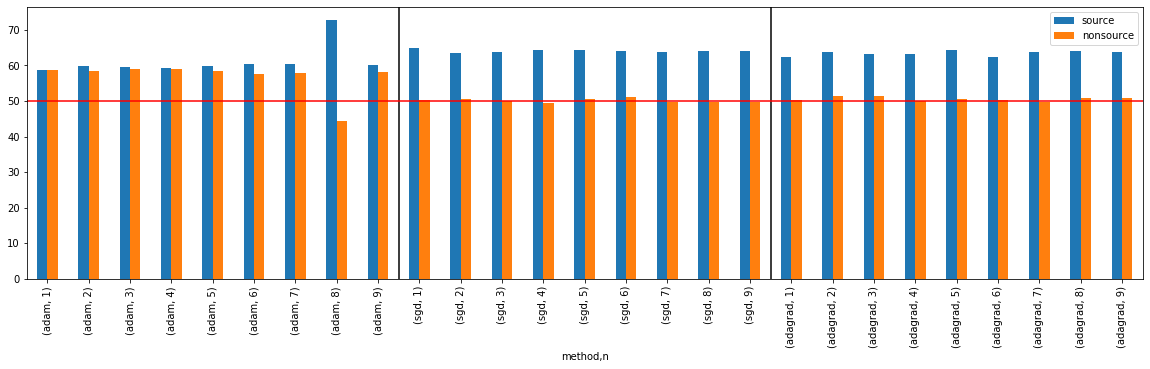

In [121]:
accuracy.plot(kind='bar', figsize=(20,5))
plt.axvline(8.5, color='k')
plt.axvline(17.5, color='k')
plt.axhline(50, color='r')

method
adagrad    AxesSubplot(0.125,0.125;0.775x0.755)
adam       AxesSubplot(0.125,0.125;0.775x0.755)
sgd        AxesSubplot(0.125,0.125;0.775x0.755)
dtype: object

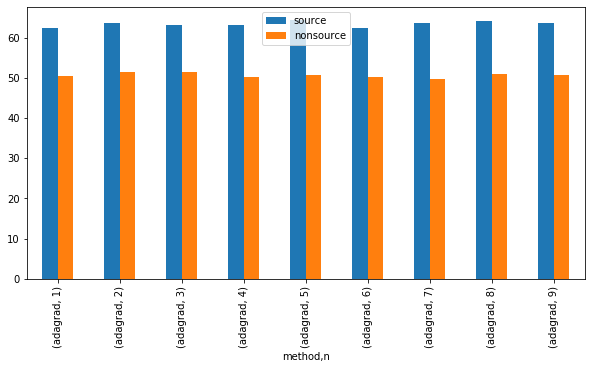

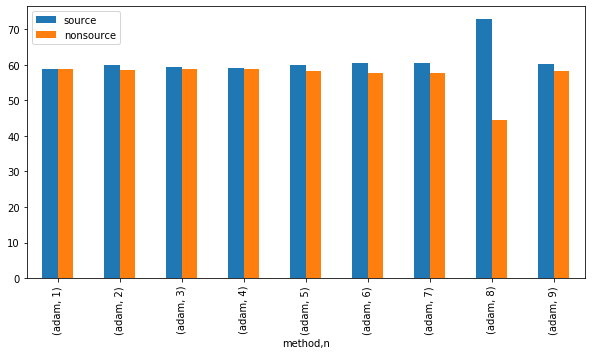

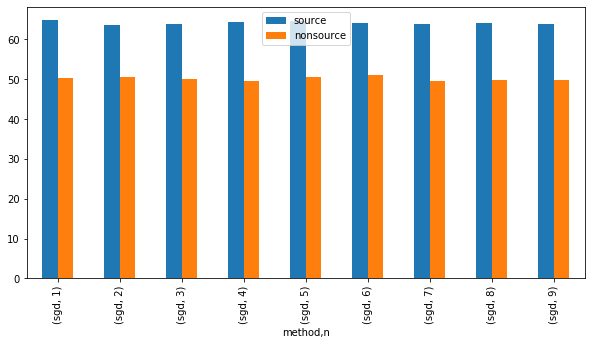

In [98]:
accuracy.groupby('method').plot(kind='bar', figsize=(10,5))

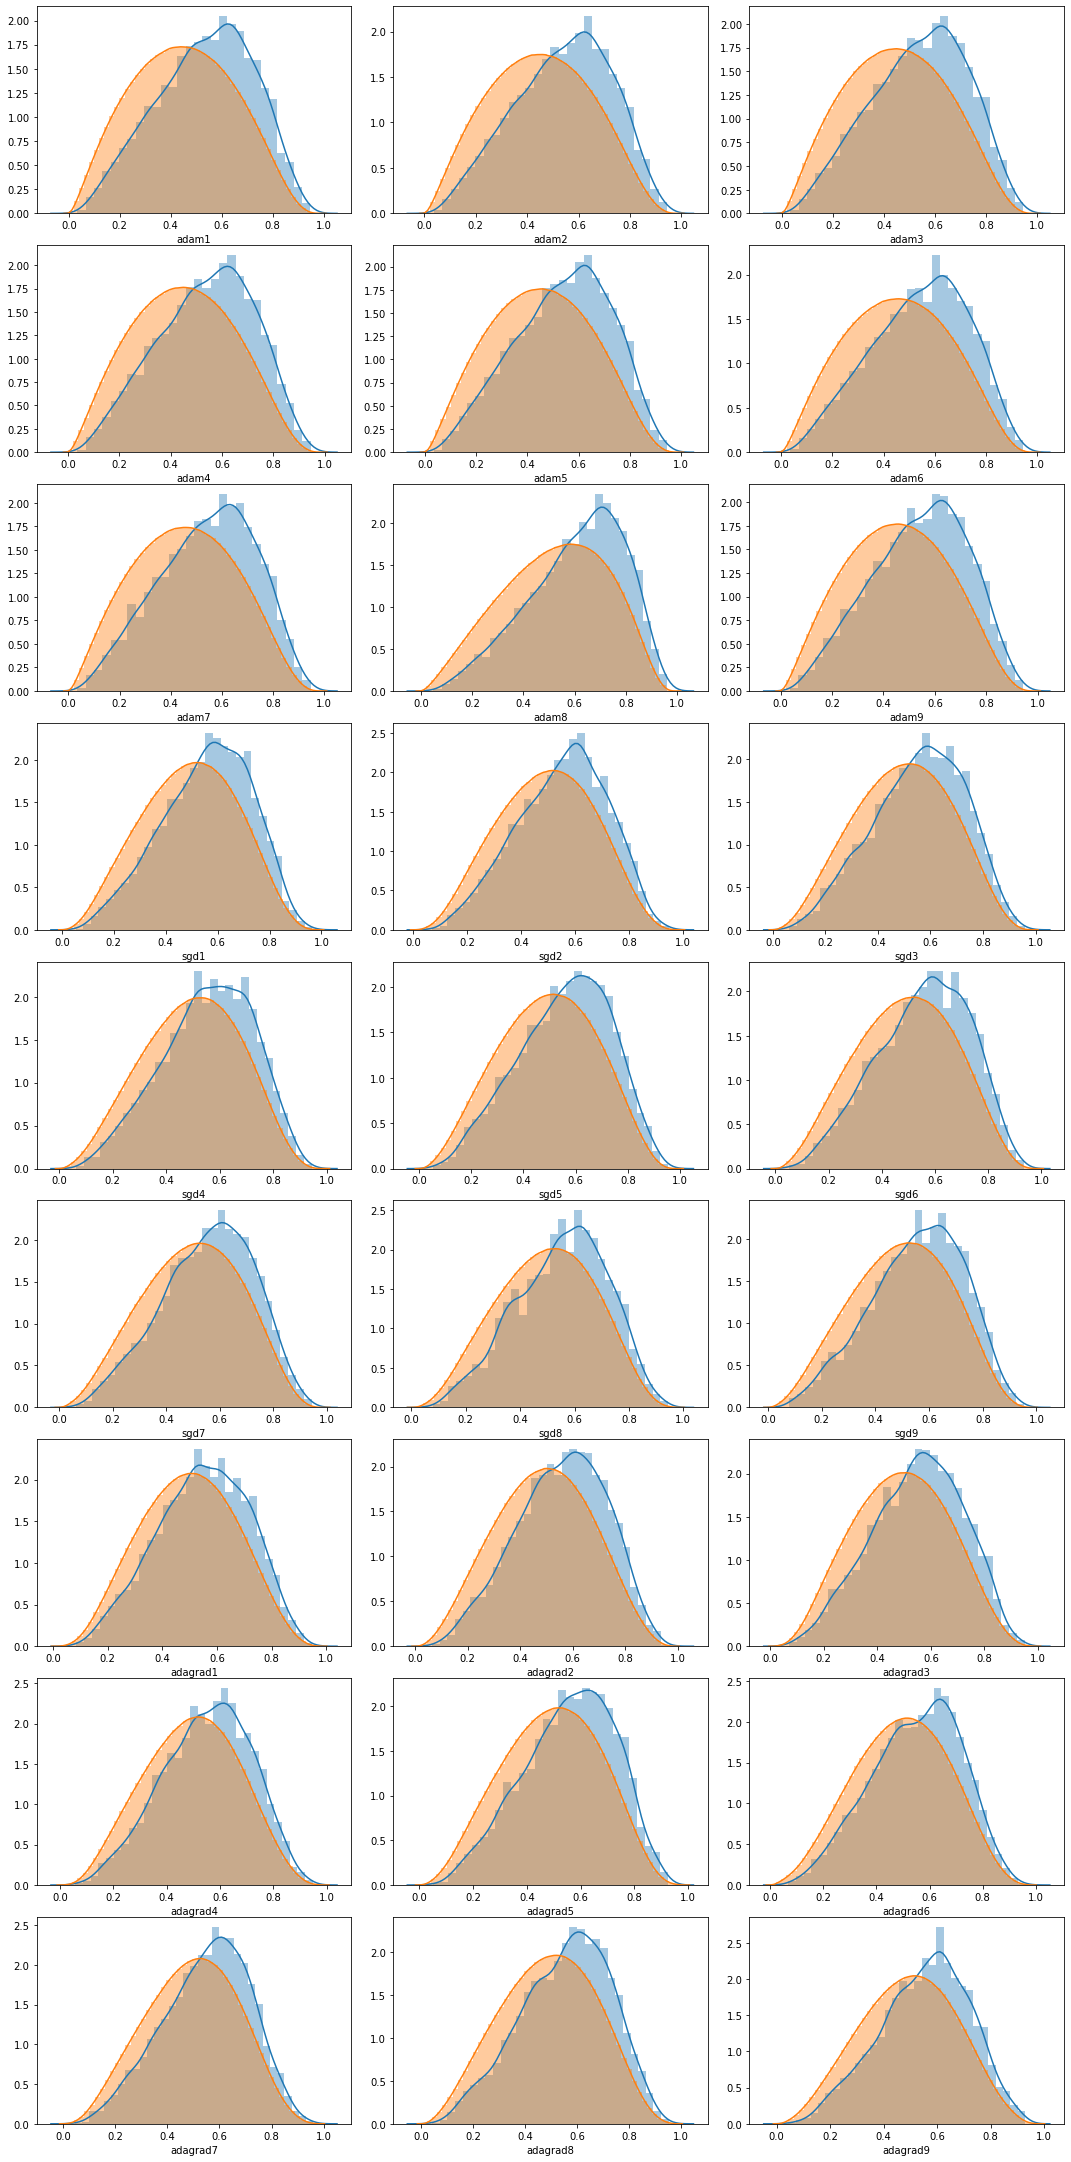

In [162]:
fig, axs = plt.subplots(len(source.columns)//3, len(source.columns)//(len(source.columns)//3), figsize=(15,30))
plt.tight_layout()
counter = 0
for (method, s), (m, ns) in zip(source.iteritems(), nonsource.iteritems()):
    assert method == m
    sns.distplot(s, ax=axs[counter//3][counter%3])
    sns.distplot(ns, ax=axs[counter//3][counter%3])
    #mannwhitneyu(s, ns)
    counter += 1

In [17]:
nbins = 100
bins_length = 1 / nbins
bins = [bins_length * x for x in range(nbins+1)]

source["bins"] = pd.cut(source["score"], bins)
nonsource["bins"] = pd.cut(nonsource["score"], bins)
df_bins = pd.DataFrame([source.rename({"score":"source"}, axis=1).groupby('bins').count().source,
                        nonsource.rename({"score":"nonsource"}, axis=1).groupby('bins').count().nonsource]
                      ).transpose()
df_bins["diff"] = df_bins.source - (df_bins.nonsource * (source.shape[0] / nonsource.shape[0] ))
df_bins["bin"] = [x.left for x in df_bins.index]
df_bins["Higher"] = df_bins["diff"].apply(lambda row: "source" if row >= 1 else "nonsource")

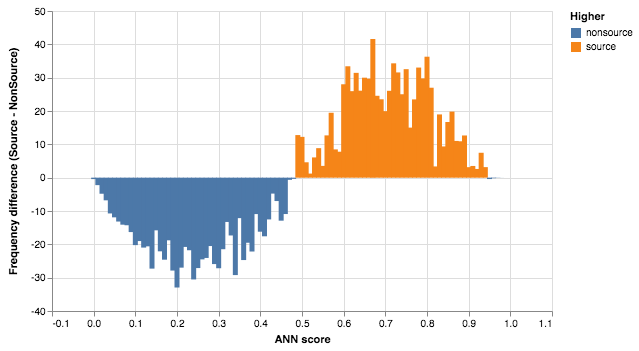

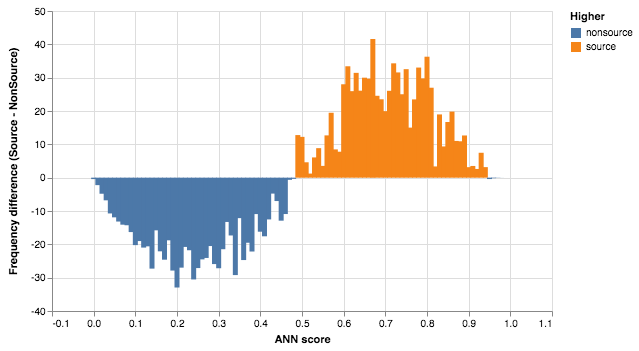

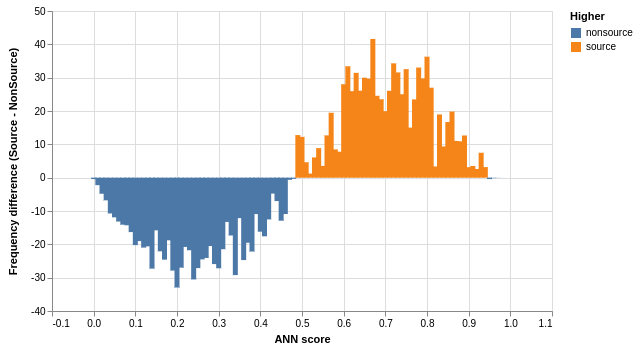

In [18]:
alt.Chart(df_bins).mark_bar().encode(
    x=alt.X('bin', title='ANN score', scale=alt.Scale(domain=[0, 1])),
    y=alt.Y('diff', scale=alt.Scale(type='linear'), title='Frequency difference (Source - NonSource)'),
    color=alt.Color('Higher')
).properties(width=500)

In [19]:
df_bins.head()

,source,nonsource,diff,bin,Higher
bins,,,,,
"(0.0, 0.01]",0,2536,-0.427586,0.00,nonsource
"(0.01, 0.02]",0,13277,-2.238587,0.01,nonsource
"(0.02, 0.03]",0,28592,-4.820795,0.02,nonsource
"(0.03, 0.04]",1,46249,-6.797879,0.03,nonsource
"(0.04, 0.05]",0,63665,-10.734328,0.04,nonsource


In [20]:
source

,score,bins
0,0.437137,"(0.43, 0.44]"
1,0.407332,"(0.4, 0.41]"
2,0.750790,"(0.75, 0.76]"
3,0.780998,"(0.78, 0.79]"
4,0.382975,"(0.38, 0.39]"
...,...,...
4622,0.482460,"(0.48, 0.49]"
4623,0.313516,"(0.31, 0.32]"
4624,0.254324,"(0.25, 0.26]"
4625,0.428891,"(0.42, 0.43]"


In [21]:
base = alt.Chart(source)

bar = base.mark_bar().encode(
    x=alt.X('score:Q', bin=alt.Bin(extent=[0, 1], step=0.05), axis=None),
    y='count()'
)

rule = base.mark_rule(color='red').encode(
    x='mean(score):Q',
    size=alt.value(5)
)

bar + rule

TypeError: Object of type Interval is not JSON serializable

alt.LayerChart(...)

In [13]:
base = alt.Chart(nonsource.iloc[:5000])

bar = base.mark_bar().encode(
    x=alt.X('score:Q', bin=alt.Bin(extent=[0, 1], step=0.05), axis=None),
    y='count()'
)

rule = base.mark_rule(color='red').encode(
    x='mean(score):Q',
    size=alt.value(5)
)

bar + rule

TypeError: Object of type Interval is not JSON serializable

alt.LayerChart(...)